In [1]:
import warnings
warnings.filterwarnings('ignore')

from datetime import datetime
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import gsw
import cartopy.crs as ccrs

from utils import make_map, subplots_structure
from load_profiles import load_vertical_profiles

In [2]:
def clean_axis(ax, list_axes=['bottom', 'right', 'left']):
    for edge_i in list_axes:
        ax.spines[edge_i].set_edgecolor("white")
    return ax

def clean_ticks(ax, left=False, bottom=False):
    if left:
        ax.yaxis.set_tick_params(labelleft=False)
        ax.set_yticks([])
    if bottom:
        ax.xaxis.set_tick_params(labelbottom=False)
        ax.set_xticks([])

In [3]:
datadir_ctd = '/home/danilo/phd/thesis/chapter_colab/scripts/section-ctd_dalton/data/umassd2/treated'
datadir_argo = '/home/danilo/phd/thesis/smax_pathways/data/argo'
datadir_glider = '/home/danilo/phd/thesis/smax_pathways/data/glider'

In [4]:
zoomed_extent= [-45, -39, -27, -22]

In [5]:
profile_fig_config = {
    'figsize': [5,10],
    'x-label': 'absolute salinity [g/kg]',
    'y-label': 'depth [m]',
    'x-range': [34.5, 37.5],
    'y-range': [-200,0],
}

order_plot = ['cast1', 'cast3.2', 'cast2', 'cast6', 'cast7']
letters = 'a b c d e'.split(' ')

In [6]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [7]:
dict_casts = load_vertical_profiles()

Processing cast1...
Processing cast2...
Processing cast3.2...
Processing cast6...
Processing cast7...


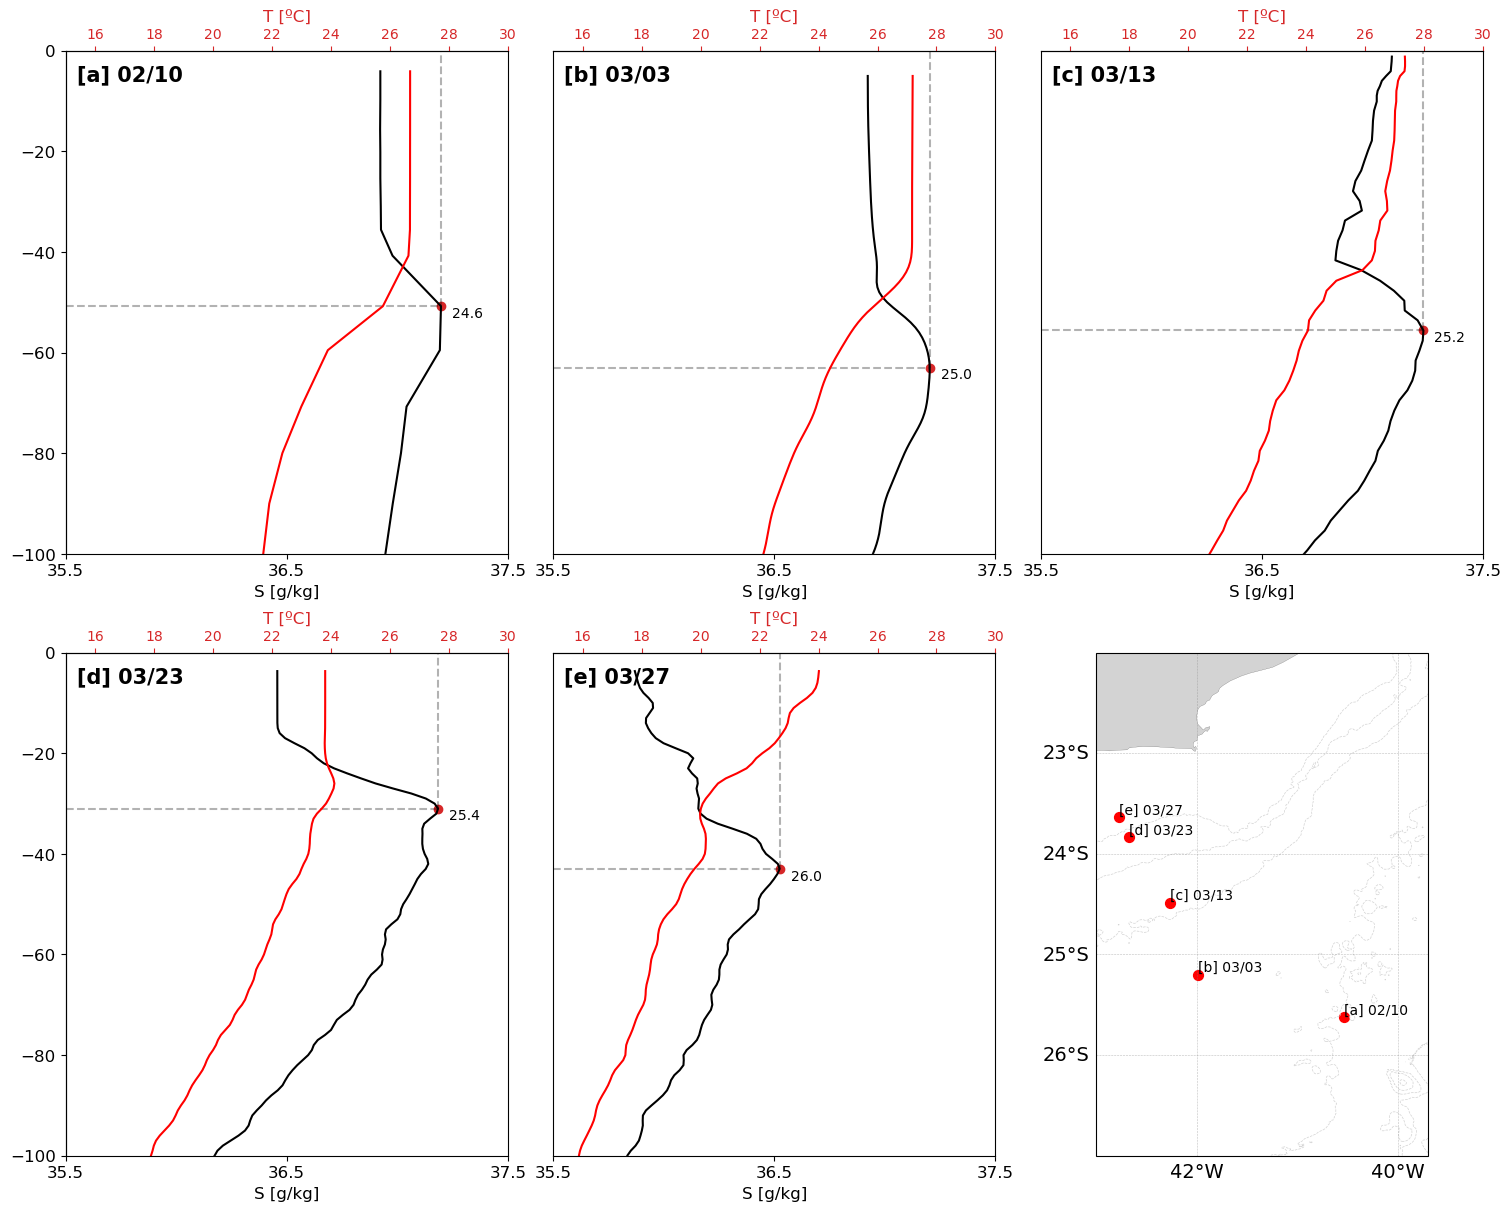

In [8]:
import matplotlib.pyplot as plt

from matplotlib.gridspec import GridSpec

fig = plt.figure(layout="constrained", figsize=(15,12))

gs = GridSpec(2, 6, figure=fig)

ax1 = fig.add_subplot(gs[0,:2])
ax2 = fig.add_subplot(gs[0,2:4])
ax3 = fig.add_subplot(gs[0,4:])

ax4 = fig.add_subplot(gs[1,:2])
ax5 = fig.add_subplot(gs[1,2:4])

axes = [ax1, ax2, ax3, ax4, ax5]

_ = clean_axis(axes[0], list_axes=['bottom', 'right'])
_ = clean_axis(axes[3], list_axes=['bottom', 'right'])

_ = clean_ticks(axes[0], bottom=True)
_ = [clean_axis(ax) for ax in [ax2, ax3, ax5]]
_ = [clean_ticks(ax, bottom=True, left=True) for ax in [ax2, ax3, ax5]]

_ = [ax.set_xlim([35.5,37.5]) for ax in axes]
_ = [ax.set_ylim([-100,0]) for ax in axes]

# plotting
for i,c in enumerate(order_plot):
    ax = axes[i]
    axT = ax.twiny()
    prof = dict_casts[c]['prof'] #keys[c]
    axT.tick_params(axis='x', colors='tab:red')
    axT.set_xlim([15,30])
    axT.set_xlabel('T [ºC]', fontsize=12, color='tab:red')
    ax.set_xlabel('S [g/kg]', fontsize=12, color='k')
    
    c = 'k'
        
    x = prof['salt']
    x2 = prof['temp']
    y = prof['dept']
    d = prof['dens'].values
    
    indmax = np.argmax(prof['salt'].values)
    
    ax.plot(x, y, c)
    axT.plot(x2, y, 'r')
    ax.scatter(x[indmax], y[indmax], marker='o', c='tab:red')

    ax.plot([35.5, x[indmax].item()], [y[indmax].item(), y[indmax].item()], ls='--', c='k', alpha=.3)
    ax.plot([x[indmax].item(), x[indmax].item()], [y[indmax].item(), 0], ls='--', c='k', alpha=.3)
    ax.text(x[indmax].item()+.05, y[indmax].item(), 
            # f"({x[indmax].item():0.2f},\n{y[indmax].item():0.2f})", 
            round(d[indmax], 1),
            ha='left', va='top')
    
    # ax.set_title(prof.attrs['time'].strftime("%m/%d"))
    # ax.text(36.8, -95, prof.attrs['time'].strftime("%m/%d"), fontweight='bold', fontsize=15)
    ax.text(35.55, -6, f'[{letters[i]}] {prof.attrs["time"].strftime("%m/%d")}', fontweight='bold', fontsize=15)
        
# axes[0].text(35.5, -120, r'open ocean $\rightarrow$', fontsize=18)
# axes[-1].text(35.5, -120, r'$\rightarrow$ outer shelf', fontsize=18)

_ = [ax.tick_params(top=False, labeltop=False, bottom=True, labelbottom=True) for ax in axes]
_ = [ax.set_xticks([35.5, 36.5, 37.5]) for ax in axes]

plt.subplots_adjust(wspace=.4)

ax = fig.add_subplot(gs[1,4:], projection = ccrs.PlateCarree())
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent([-43, -39.7, -27, -22])

bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -2000, -3000, -4000], 
                         colors=('lightgray'), linewidths=(0.5), linestyles=('--'))

varbs = [['LONGITUDE', 'LATITUDE'],
         ['LONGITUDE', 'LATITUDE'],
         ['LONGITUDE', 'LATITUDE'],
         ['lon', 'lat'],
         [],
        ]

# plotting
cont = 0
letters = 'a c b d e'.split(' ')
# for i,c in enumerate(order_plot):
for cast,values in dict_casts.items():
    prof = values['prof'] #keys[c]

    str_time = f'[{letters[cont]}] {values["time"].strftime("%m/%d")}'
    xlon = prof.attrs['lon']
    ylat = prof.attrs['lat']
    cont += 1
    c='red'
    
    ax.scatter(xlon, ylat, c=c, s=50)
    ax.text(xlon, ylat, str_time, ha='left', va='bottom')

for ax in axes:
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    
fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_train_profiles_new.png', bbox_inches="tight", dpi=300)

# Supplementary Figure TS Diagram

In [ ]:
def parametric_isopycnal():
    
    T = np.linspace(10,30, 50)
    S = np.linspace(34, 38, 50)
    T,S = np.meshgrid(T,S)
    
    rho = gsw.sigma0(S, T) # + 1000
        
    return S,T,rho

def build_fig_structure(xlim, ylim):
    S,T,rho = parametric_isopycnal()
    
    fig,ax = plt.subplots(figsize=(10,10))
    cs = ax.contour(S, T, rho, colors='grey', zorder=1, linestyles='--', linewidths=0.5)
    cl=plt.clabel(cs, fontsize=10, inline=True, fmt='%.1f')
    ax.set(
        xlim=xlim,
        ylim=ylim,
        xlabel='absolute salinity [g/kg]',
        ylabel='temperature [oC]'
    )
    
    return fig,ax

In [ ]:
import numpy as np
keys = list(dict_casts.keys())
order_plot = ['cast1', 'cast3.2', 'cast2', 'cast6', 'cast7']

colors = ['tab:green', 'tab:blue', 'tab:red', 'black', 'tab:orange', 'orange']
colors = ['k'] * len(keys)
markers = ['*', 'x', 'o', 'D', '+']

fig,ax = build_fig_structure(xlim=[34, 38], ylim=[15,30])

cont = 0.1
for i,c in enumerate(order_plot):
    prof = dict_casts[c]['prof']
    
    xT = prof['temp'].values
    xS = prof['salt'].values
    sD = prof['dens'].values
    y = prof['dept'].values
    indy_100m = np.where(prof['dept'].values >= -100)[0]
    time = prof.attrs['time'].strftime("%m/%d")
    
    cont += 0.1
    ax.scatter(xS[indy_100m], xT[indy_100m], color=colors[i], label=time, marker=markers[i])

ax.text(35., 24, 'Coastal Water\n(CW)', fontsize=20, c='tab:orange', ha='center')
ax.text(35.5, 17, 'South Atlantic\nCentral Water\n(SACW)', fontsize=20, ha='center', c='tab:blue')
ax.text(35.5, 16.7, 'Cerda and Castro [2014]', fontsize=8, ha='center', c='tab:blue')
ax.text(37, 27.8, 'Tropical Water\n(TW)', fontsize=20, ha='center', va='bottom', c='tab:red')
ax.text(37, 27.6, 'Cerda and Castro [2014]', fontsize=8, ha='center', c='tab:red')

plt.legend(loc='lower right')
fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_supp_tsdiagram.png', 
            bbox_inches="tight", dpi=300)